# Fuzzy Cognitive Map (FCM): Plant Watering System
Same workflow as the hostel template, applied to the plant water adjustment project.

**Concepts (all scaled 0–1):** Temperature, Humidity, Sunlight, Soil_Moisture, Water_Adjustment, Plant_Health.

Install once if needed: `pip install fcmpy matplotlib pandas numpy`

## 0. Dataset
No plant dataset was supplied, so this cell creates a **synthetic** `plant_watering_dataset.csv` (300 rows). `Water_Adjustment` comes from the same fuzzy rules as `Fuzzy.py`. If you have real data, put it in the same folder with the same column names and this cell is skipped.

In [1]:
import os
import numpy as np
import pandas as pd

# ---- fuzzy water-adjustment rules (same sets/rules as Fuzzy.py), numpy only ----
def trimf(x, a, b, c):
    x = np.asarray(x, dtype=float)
    y = np.zeros_like(x)
    if b > a:
        m = (x > a) & (x < b); y[m] = (x[m] - a) / (b - a)
    y[x == b] = 1.0
    if c > b:
        m = (x > b) & (x < c); y[m] = (c - x[m]) / (c - b)
    return y

def trapmf(x, a, b, c, d):
    x = np.asarray(x, dtype=float)
    y = np.zeros_like(x)
    y[(x >= b) & (x <= c)] = 1.0
    if b > a:
        m = (x > a) & (x < b); y[m] = (x[m] - a) / (b - a)
    if d > c:
        m = (x > c) & (x < d); y[m] = (d - x[m]) / (d - c)
    return y

CHANGE_U = np.arange(-30, 20.01, 0.1)
OUT_SETS = [trimf(CHANGE_U, -31, -30, -28), trimf(CHANGE_U, -25, -15, -10),
            trimf(CHANGE_U, -15, -8, 0),    trimf(CHANGE_U, -5, 0, 5),
            trimf(CHANGE_U, 0, 8, 15),      trimf(CHANGE_U, 10, 15, 20)]

def fuzzy_percent_change(t):
    strengths = [trapmf(t, -10, -10, 0, 5)[()], trimf(t, 5, 10, 15)[()],
                 trimf(t, 10, 15, 20)[()],      trimf(t, 20, 25, 30)[()],
                 trimf(t, 25, 30, 35)[()],      trimf(t, 30, 35, 40)[()]]
    agg = np.zeros_like(CHANGE_U)
    for s, mf in zip(strengths, OUT_SETS):
        agg = np.fmax(agg, np.fmin(s, mf))
    return 0.0 if agg.sum() == 0 else float((CHANGE_U * agg).sum() / agg.sum())

# ---- synthetic plant-watering dataset (all concepts scaled to 0-1) ----
if not os.path.exists("plant_watering_dataset.csv"):
    rng = np.random.default_rng(42)
    n = 300
    temp_c = rng.uniform(-10, 40, n)                       # °C
    humidity = rng.uniform(0.1, 1.0, n)
    sunlight = rng.uniform(0.0, 1.0, n)
    pct = np.array([fuzzy_percent_change(t) for t in temp_c])   # fuzzy % change

    temperature = (temp_c + 10) / 50
    water_adj = (pct + 30) / 50
    soil = np.clip(0.35 + 0.35 * humidity + 0.35 * water_adj
                   - 0.30 * temperature - 0.10 * sunlight
                   + rng.normal(0, 0.05, n), 0, 1)
    health = np.clip(0.2 + 0.6 * soil - 0.3 * np.abs(temperature - 0.6)
                     + 0.15 * sunlight + rng.normal(0, 0.05, n), 0, 1)

    pd.DataFrame({
        "Temperature": temperature, "Humidity": humidity, "Sunlight": sunlight,
        "Soil_Moisture": soil, "Water_Adjustment": water_adj, "Plant_Health": health,
    }).round(4).to_csv("plant_watering_dataset.csv", index=False)
    print("Dataset created: plant_watering_dataset.csv")
else:
    print("Using existing plant_watering_dataset.csv")

Using existing plant_watering_dataset.csv


## 1. Load data and build the weight matrix (correlation)

In [2]:
from fcmpy import FcmSimulator, FcmIntervention
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Load dataset
df = pd.read_csv('plant_watering_dataset.csv')

# Compute correlation matrix (used as weight matrix)
corr = df.corr().to_numpy(copy=True)

# Set diagonal to 0 (no self-loops)
np.fill_diagonal(corr, 0)
weight_matrix = pd.DataFrame(corr, index=df.columns, columns=df.columns)

print(weight_matrix)

                  Temperature  Humidity  ...  Water_Adjustment  Plant_Health
Temperature          0.000000  0.049506  ...          0.985590      0.482084
Humidity             0.049506  0.000000  ...          0.035130      0.520694
Sunlight            -0.007567 -0.173774  ...         -0.009028      0.133849
Soil_Moisture        0.199075  0.815456  ...          0.215077      0.566761
Water_Adjustment     0.985590  0.035130  ...          0.000000      0.470740
Plant_Health         0.482084  0.520694  ...          0.470740      0.000000

[6 rows x 6 columns]


## 2. Initial state (mean of each concept)

In [3]:
init_state = df.mean().to_dict()
print(init_state)

{'Temperature': 0.4866546666666666, 'Humidity': 0.5547873333333333, 'Sunlight': 0.49719899999999995, 'Soil_Moisture': 0.4875976666666667, 'Water_Adjustment': 0.3966676666666667, 'Plant_Health': 0.4873046666666666}


## 3. Simulation: sigmoid vs tanh

In [4]:
sim = FcmSimulator()

res_sigmoid = sim.simulate(
    initial_state=init_state,
    weight_matrix=weight_matrix,
    transfer='sigmoid',
    inference='mKosko',
    thresh=0.001,
    iterations=50,
    l=1
)

res_hyperbolic = sim.simulate(
    initial_state=init_state,
    weight_matrix=weight_matrix,
    transfer='tanh',
    inference='mKosko',
    thresh=0.001,
    iterations=50,
    l=1
)

The values converged in the 6 state (e <= 0.001)
The values converged in the 8 state (e <= 0.001)


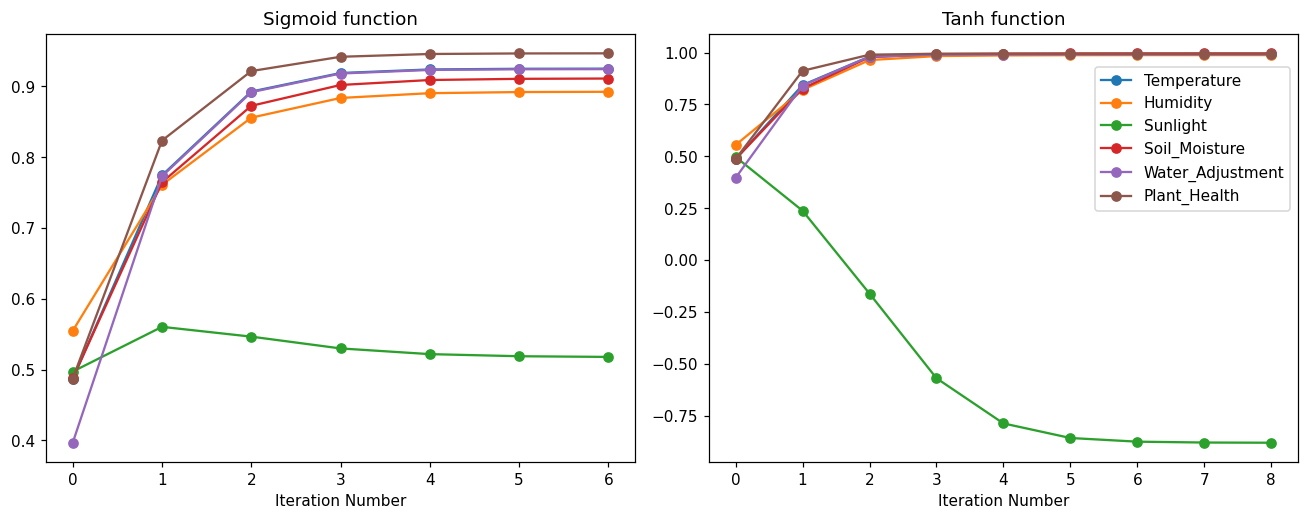

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

res_sigmoid.plot(ax=axes[0], marker='o')
axes[0].get_legend().remove()
axes[0].set_xlabel("Iteration Number")
axes[0].set_title("Sigmoid function")

res_hyperbolic.plot(ax=axes[1], marker='o')
axes[1].legend(bbox_to_anchor=(1, 0.94))
axes[1].set_xlabel("Iteration Number")
axes[1].set_title("Tanh function")

plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.show()

## 4. Intervention: heatwave
Temperature is pushed up (+0.3) to see how watering need, soil moisture and plant health respond.

In [6]:
inter = FcmIntervention(FcmSimulator)

inter.initialize(
    initial_state=init_state,
    weight_matrix=weight_matrix,
    transfer="tanh",
    inference="mKosko",
    thresh=0.001,
    iterations=50,
    l=1
)

# Baseline
baseline = inter.test_results["baseline"]

# Intervention: heatwave (increase Temperature)
inter.add_intervention(
    "Intervention_Heatwave",
    type="continuous",
    impact={"Temperature": 0.3},
    effectiveness=1
)

inter.test_intervention("Intervention_Heatwave", iterations=50)

intervention_result = inter.test_results["Intervention_Heatwave"]

The values converged in the 8 state (e <= 0.001)
The values converged in the 8 state (e <= 0.001)


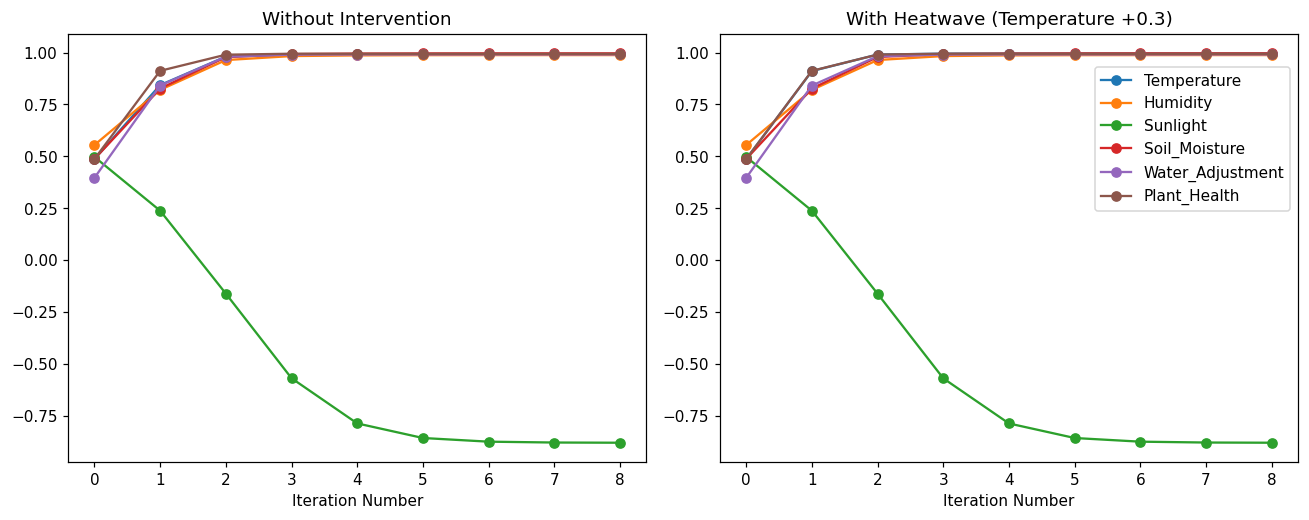

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

baseline.plot(ax=axes[0], marker='o')
axes[0].get_legend().remove()
axes[0].set_xlabel("Iteration Number")
axes[0].set_title("Without Intervention")

intervention_result.plot(ax=axes[1], marker='o')
axes[1].legend(bbox_to_anchor=(1, 0.94))
axes[1].set_xlabel("Iteration Number")
axes[1].set_title("With Heatwave (Temperature +0.3)")

plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.show()

## 5. Convergence, equilibrium and comparison

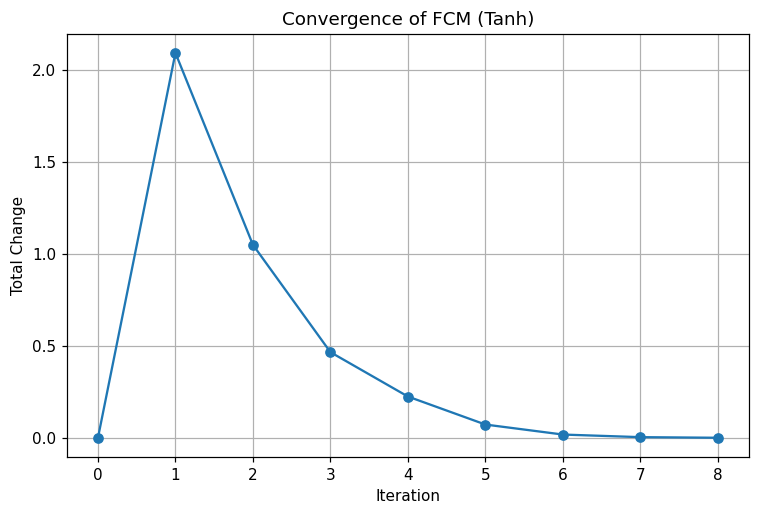

In [8]:
# Convergence check (difference between iterations)
diff = res_hyperbolic.diff().abs()

plt.figure(figsize=(8,5))
diff.sum(axis=1).plot(marker='o')
plt.xlabel("Iteration")
plt.ylabel("Total Change")
plt.title("Convergence of FCM (Tanh)")
plt.grid()
plt.show()

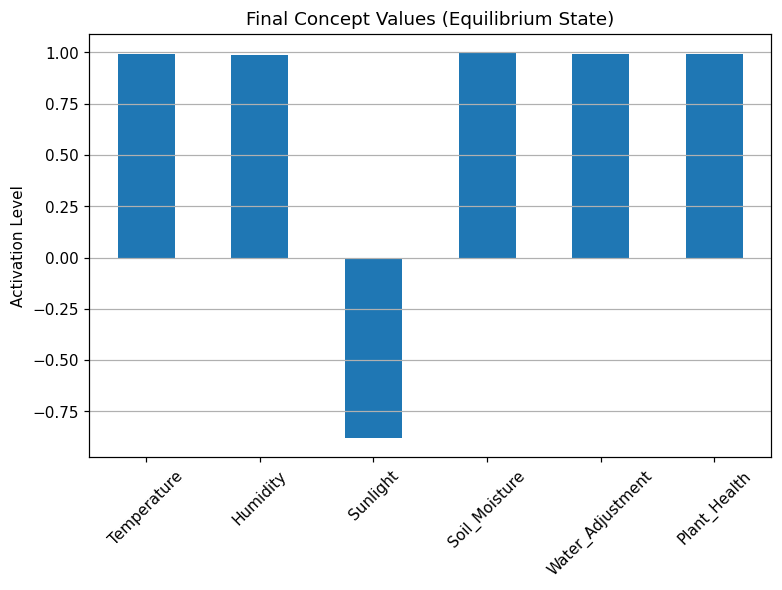

In [9]:
final_state = res_hyperbolic.iloc[-1]

final_state.plot(kind='bar', figsize=(8,5))
plt.title("Final Concept Values (Equilibrium State)")
plt.ylabel("Activation Level")
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

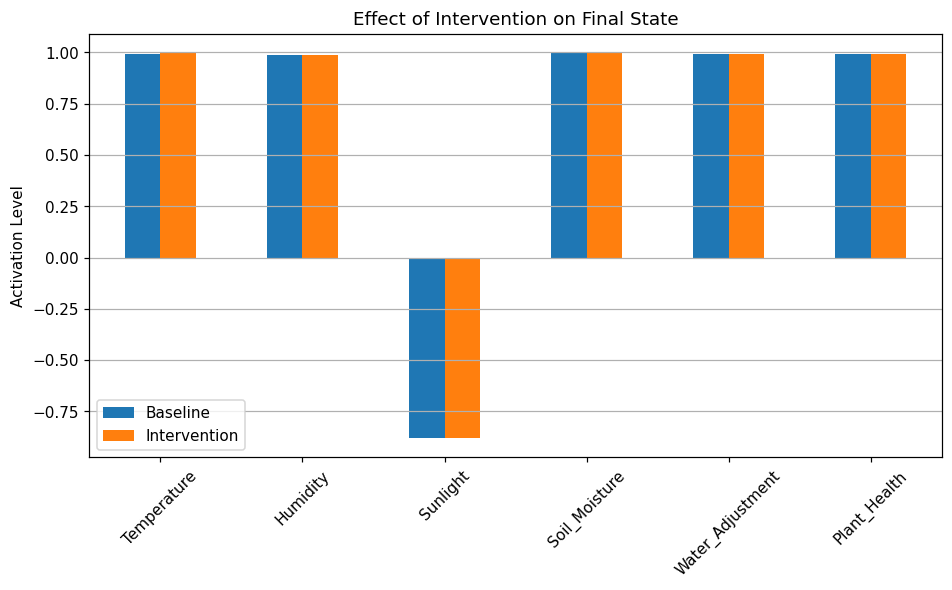

In [10]:
comparison = pd.DataFrame({
    "Baseline": baseline.iloc[-1],
    "Intervention": intervention_result.iloc[-1]
})

comparison.plot(kind='bar', figsize=(10,5))
plt.title("Effect of Intervention on Final State")
plt.ylabel("Activation Level")
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()